# Number formats for neural networks: fp32, fp16, and bf16

Every weight, activation, and gradient in a neural network is stored as a **floating-point number**. Which format is used decides how much memory the model takes, how fast the GPU can compute, and whether training quietly goes wrong. Phrases from the fine-tuning lectures, such as "load in fp16", "bf16 is not supported on a T4", "keep an fp32 master copy", or "the loss became NaN", all come down to how these formats store numbers.

This notebook covers what you need to follow those lectures, with small worked examples you can change and rerun.

**What you will learn**

1. How a floating-point number is stored as a **sign**, an **exponent**, and a **mantissa**, worked through for one number.
2. How fp32, fp16, and bf16 divide their bits, and what that means for **range** and **precision**.
3. Why storing frozen weights in 16-bit is usually fine.
4. The three ways low precision breaks training (lost updates, overflow, underflow), and the fixes frameworks use: **fp32 master weights**, **loss scaling**, and **mixed precision**.
5. Which format to choose on which GPU, and what all of this means for **LoRA** and **QLoRA**.

**Prerequisites:** Python and PyTorch tensors. Powers of two (2³ = 8, 2⁻¹ = 0.5) are the only mathematics needed.

**Setup:** PyTorch and matplotlib only. Runs on a CPU in a few seconds, with no downloads.

**Next:** [PEFT and LoRA](peft_lora.ipynb) and [Quantization and QLoRA](quantization_qlora.ipynb) use these formats throughout.

In [1]:
import math

import matplotlib.pyplot as plt
import torch
from matplotlib.patches import FancyBboxPatch, Rectangle

torch.manual_seed(0)

# name: (PyTorch dtype, exponent bits, mantissa bits, exponent bias)
FORMATS = {
    "fp32": (torch.float32, 8, 23, 127),
    "fp16": (torch.float16, 5, 10, 15),
    "bf16": (torch.bfloat16, 8, 7, 127),
}
COLORS = {"sign": "#e74c3c", "exponent": "#5dade2", "mantissa": "#58d68d"}
FMT_COLORS = {"fp32": "#34495e", "fp16": "#e67e22", "bf16": "#8e44ad"}


def stored(x, fmt):
    """The value actually stored when x is converted to the format (round to nearest)."""
    return torch.tensor(float(x), dtype=FORMATS[fmt][0]).double().item()


def to_bits(x, fmt):
    """(sign, exponent, mantissa) bit strings of x stored in the format."""
    dtype, e, m, _ = FORMATS[fmt]
    t = torch.tensor(float(x), dtype=dtype)
    raw = t.view(torch.int32 if dtype == torch.float32 else torch.int16).item() & ((1 << (1 + e + m)) - 1)
    s = format(raw, f"0{1 + e + m}b")
    return s[0], s[1:1 + e], s[1 + e:]


def show(x):
    """Print the bits and the stored value of x in each format."""
    print(f"x = {x!r}")
    for fmt in FORMATS:
        s, e, m = to_bits(x, fmt)
        v = stored(x, fmt)
        err = abs(v - x) if math.isfinite(v) else float("inf")
        print(f"  {fmt}  {s} | {e} | {m:<23}  stored {v!r:<24} error {err:.2e}")


print("PyTorch", torch.__version__)

PyTorch 2.4.0+cu121


## 1. Why number formats matter

A format with fewer bits per number has three effects:

| | 32-bit (fp32) | 16-bit (fp16 or bf16) |
| --- | --- | --- |
| **Memory** per number | 4 bytes | 2 bytes |
| **Speed** on modern GPUs | baseline | much faster matrix multiplication on tensor cores, and half the data to move |
| **Accuracy** | about 7 significant decimal digits | about 2–3 significant digits, and a smaller range for fp16 |

For a 1.5-billion-parameter model such as Qwen2.5-1.5B, the weights alone take about 6.2 GB in fp32 and 3.1 GB in a 16-bit format. Halving memory and speeding up computation is why 16-bit formats are now standard. The price is accuracy, and the rest of this notebook is about exactly what is lost and how to live with it.

## 2. Floating point is scientific notation in binary

In decimal scientific notation, $-625 = -6.25 \times 10^{2}$: a sign, some digits, and an exponent that says where the decimal point goes. Floating point does the same in base 2:

$$\text{value} = (-1)^{\text{sign}} \times 1.\text{mantissa}_2 \times 2^{\,\text{exponent} - \text{bias}}$$

| Field | What it stores | What it controls |
| --- | --- | --- |
| **sign** (1 bit) | 0 for positive, 1 for negative | the sign |
| **exponent** (*e* bits) | the power of two, stored with a **bias** added so it is never negative | the **range**: how large or small a number can be |
| **mantissa** (*m* bits), also called the fraction or significand | the binary digits after the leading `1.` | the **precision**: how finely nearby numbers can be told apart |

Two details:

- **The leading 1 is not stored.** After normalizing, a nonzero binary number always starts with `1.`, so storing it would waste a bit. An *m*-bit mantissa therefore gives *m* + 1 significant bits.
- **The bias** lets the exponent field be an unsigned integer. With 8 exponent bits the bias is 127: a stored 130 means 2³, and a stored 123 means 2⁻⁴.

### Worked example: encoding −6.25

Encoding means working backwards from a number to the three fields. The three formats use these field widths:

| Format | Sign bits | Exponent bits | Bias | Mantissa bits |
| --- | --- | --- | --- | --- |
| fp32 | 1 | 8 | 127 | 23 |
| fp16 | 1 | 5 | 15 | 10 |
| bf16 | 1 | 8 | 127 | 7 |

**Step 0: Set the sign aside.** Floating point stores the sign separately from the size of the number (*sign-magnitude*). So **sign = 1** (negative), and from here on we encode only the magnitude **6.25**.

**Step 1: Write 6.25 in binary.** Convert the integer part and the fractional part separately.

*Integer part, 6.* Divide by 2 repeatedly. The remainders, read from the bottom up, are the binary digits:

| Division | Quotient | Remainder |
| --- | --- | --- |
| 6 ÷ 2 | 3 | **0** |
| 3 ÷ 2 | 1 | **1** |
| 1 ÷ 2 | 0 | **1** |

So $6 = 110_2$.

*Fractional part, 0.25.* Double it repeatedly. Each doubling moves the next binary digit in front of the point, so the integer parts, read from the top down, are the digits after the point:

| Step | Result | Digit |
| --- | --- | --- |
| 0.25 × 2 | 0.5 | **0** |
| 0.5 × 2 | 1.0 | **1** (nothing left, so stop) |

So $0.25 = 0.01_2$. Together, $6.25 = 110.01_2$. Each digit is a place value, just as in decimal:

| Digit of $110.01_2$ | 1 | 1 | 0 | . | 0 | 1 |
| --- | --- | --- | --- | --- | --- | --- |
| Place value | $2^2 = 4$ | $2^1 = 2$ | $2^0 = 1$ | | $2^{-1} = \frac12$ | $2^{-2} = \frac14$ |
| Contribution | 4 | 2 | 0 | | 0 | $\frac14$ |

The `0` in `110` is the 1s place: 6 is even, so it contains no 1. No digit here is a sign bit; the sign was handled in Step 0. The fraction ended after two digits because $0.25 = 2^{-2}$ is a power of two. For most decimal fractions it never ends: $0.1 = 0.0\overline{0011}_2$ repeats forever, just as $\frac13 = 0.333\ldots$ does in decimal. A format keeps only a fixed number of mantissa bits, so 0.1 must be **rounded**: every format stores only an approximation of it, and formats differ in how close that approximation is.

**Step 2: Normalize** so that a single 1 stands before the point. Moving the point 2 places to the left divides the digits by $2^2$, so we multiply by $2^2$ to keep the value unchanged:

$$110.01_2 = 1.1001_2 \times 2^{2}$$

Check: $1.1001_2 = 1 + \frac12 + \frac1{16} = 1.5625$, and $1.5625 \times 4 = 6.25$. This is binary scientific notation, just as $625 = 6.25 \times 10^2$ in decimal.

**Step 3: Read off the mantissa.** The leading `1.` is not stored, so the mantissa is the digits after the point, `1001`. Pad it with zeros **on the right** to fill the field. These are fractional digits, so trailing zeros do not change the value, just as $0.1001 = 0.1001000$:

| Format | Mantissa field |
| --- | --- |
| fp32 (23 bits) | `1001` followed by 19 zeros |
| fp16 (10 bits) | `1001000000` |
| bf16 (7 bits) | `1001000` |

**Step 4: Add the bias to the exponent.** The true exponent is 2, and the stored exponent is 2 + bias:

- fp32 and bf16 (bias 127): 2 + 127 = **129** = 128 + 1 = `10000001`
- fp16 (bias 15): 2 + 15 = **17** = 16 + 1 = `10001`

**Step 5: Assemble the fields** in the order sign | exponent | mantissa:

```text
fp32   1 | 10000001 | 10010000000000000000000
fp16   1 | 10001    | 1001000000
bf16   1 | 10000001 | 1001000
```

**Step 6: Decode to check.** For fp16: $(-1)^1 \times 1.1001_2 \times 2^{17 - 15} = -1.5625 \times 4 = -6.25$.

The cell below asks PyTorch to store −6.25 in each format and prints the actual bits. They should match Step 5.

In [20]:
show(-6.25)

x = -6.25
  fp32  1 | 10000001 | 10010000000000000000000  stored -6.25                    error 0.00e+00
  fp16  1 | 10001 | 1001000000               stored -6.25                    error 0.00e+00
  bf16  1 | 10000001 | 1001000                  stored -6.25                    error 0.00e+00


**Reading the output**

- All three formats store −6.25 **exactly**: it needs only four mantissa bits, and every format has at least seven.
- fp32 and bf16 have the same sign and exponent bits. The bf16 mantissa is the **first 7 bits** of the fp32 mantissa. bf16 is literally the top half of fp32.
- fp16 uses a different exponent field (5 bits, bias 15), so its bits look different even though the value is the same.

## 3. Three formats, side by side

All three formats use the same recipe. They differ only in how many bits go to the exponent and how many to the mantissa.

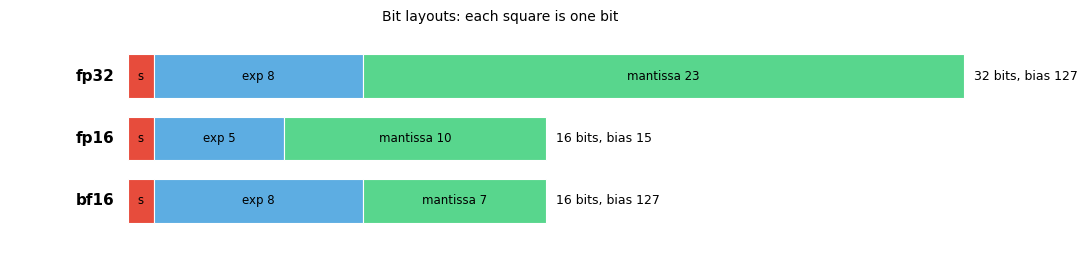

In [22]:
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.set_xlim(-4.5, 33); ax.set_ylim(-0.6, 3.1); ax.axis("off")
for row, fmt in enumerate(["fp32", "fp16", "bf16"]):
    _, e, m, bias = FORMATS[fmt]
    y = 2 - row
    ax.text(-0.5, y + 0.35, fmt, ha="right", va="center", fontsize=11, weight="bold")
    x = 0
    for field, width in (("sign", 1), ("exponent", e), ("mantissa", m)):
        ax.add_patch(Rectangle((x, y), width, 0.7, fc=COLORS[field], ec="white", lw=0.8))
        label = {"sign": "s", "exponent": f"exp {e}", "mantissa": f"mantissa {m}"}[field]
        ax.text(x + width / 2, y + 0.35, label, ha="center", va="center", fontsize=8.5)
        x += width
    ax.text(x + 0.4, y + 0.35, f"{1 + e + m} bits, bias {bias}", va="center", fontsize=9)
ax.set_title("Bit layouts: each square is one bit", fontsize=10)
plt.tight_layout(); plt.show()

In [23]:
print(f"{'':<6}{'largest':>13}{'smallest normal':>18}{'gap above 1.0':>15}{'decimal digits':>16}")
for fmt, (dtype, e, m, bias) in FORMATS.items():
    fi = torch.finfo(dtype)
    print(f"{fmt:<6}{fi.max:>13.4g}{fi.tiny:>18.4g}{fi.eps:>15.3g}{(m + 1) * math.log10(2):>16.1f}")

            largest   smallest normal  gap above 1.0  decimal digits
fp32      3.403e+38         1.175e-38       1.19e-07             7.2
fp16       6.55e+04         6.104e-05       0.000977             3.3
bf16       3.39e+38         1.175e-38        0.00781             2.4


**Reading the output**

| | Range (set by the exponent) | Precision (set by the mantissa) |
| --- | --- | --- |
| **fp32** | about 10⁻³⁸ to 3.4 × 10³⁸ | gap above 1.0 is 2⁻²³ ≈ 1.2 × 10⁻⁷: about 7 decimal digits |
| **fp16** | only 6.1 × 10⁻⁵ to **65,504** (normal numbers) | gap 2⁻¹⁰ ≈ 0.001: about 3 digits |
| **bf16** | the **same as fp32** | gap 2⁻⁷ ≈ 0.008: about 2 digits |

- The **gap above 1.0** (called *machine epsilon*) is $2^{-m}$: each mantissa bit halves it.
- "Decimal digits" is $(m + 1) \times \log_{10} 2$: the *m* stored bits plus the hidden leading 1.
- **fp16** spends more bits on precision and has a narrow range. **bf16** ("brain floating point", introduced at Google Brain for its TPUs) keeps the fp32 range and gives up precision. The two 16-bit formats make opposite trade-offs, and Section 6 shows when each one fails.
- Because bf16 is the top half of fp32 (Section 2), converting fp32 to bf16 only rounds the mantissa to 7 bits. It is cheap, and anything that fits in fp32 fits in bf16 without overflowing.

## 4. Range and precision made visible

### Step size: why the gap doubles at every power of two

The gap above 1.0 from Section 3 is only the first case of a general rule. Every normal number has the form

$$\text{value} = 1.b_1 b_2 \dots b_m \times 2^{e}$$

Within one exponent *e*, only the *m* mantissa bits can change. Flipping the last bit changes the $1.b_1 \dots b_m$ part by $2^{-m}$, and that change is multiplied by $2^{e}$ like the rest of the number:

$$\text{step} = 2^{-m} \times 2^{e}$$

For fp16 (*m* = 10):

| Range | Exponent *e* | Step |
| --- | --- | --- |
| 1 to 2 | 0 | 2⁻¹⁰ = 1/1024 |
| 2 to 4 | 1 | 2⁻¹⁰ × 2 = 1/512 |
| 4 to 8 | 2 | 2⁻¹⁰ × 4 = 1/256 |
| 1024 to 2048 | 10 | 2⁰ = 1 |
| 32,768 to 65,504 (the largest fp16 value) | 15 | 2⁵ = 32 |

**Worked example: the number after 2.0 in fp16.**

$$2.0 = 1.0000000000_2 \times 2^1$$
$$\text{next} = 1.0000000001_2 \times 2^1 = \left(1 + \tfrac{1}{1024}\right) \times 2 = 2 + \tfrac{1}{512}$$

The mantissa took the same smallest step as between 1 and 2. The factor $2^1$ doubled its size.

Another way to see it: the 10 mantissa bits give exactly $2^{10} = 1024$ evenly spaced values in **every** range from $2^e$ to $2^{e+1}$. Between 1 and 2 they are spread over a width of 1, so the step is 1/1024. Between 2 and 4 the same 1024 values are spread over a width of 2, so the step is 1/512. bf16 has only 7 mantissa bits, so it has 128 values per range: steps of 1/128 between 1 and 2 and 1/64 between 2 and 4, always 8 times the fp16 step.

The cell below asks PyTorch for the actual next representable values. `torch.nextafter(x, y)` returns the closest number to `x` in the direction of `y` that the format can store.

In [2]:
from fractions import Fraction


def next_values(start, dtype, n=3):
    """start and the next n representable values above it in the given dtype."""
    x = torch.tensor(start, dtype=dtype)
    up = torch.tensor(float("inf"), dtype=dtype)
    vals = [x]
    for _ in range(n):
        vals.append(torch.nextafter(vals[-1], up))
    return [v.item() for v in vals]


print(f"{'range':<18}{'fp16 step':>11}{'bf16 step':>11}   first fp16 values in the range")
for start, label in ((1.0, "1 to 2"), (2.0, "2 to 4"), (4.0, "4 to 8"), (1024.0, "1024 to 2048"), (32768.0, "32768 to 65504")):
    fp16_vals = next_values(start, torch.float16)
    bf16_vals = next_values(start, torch.bfloat16)
    fp16_step = Fraction(fp16_vals[1] - fp16_vals[0])
    bf16_step = Fraction(bf16_vals[1] - bf16_vals[0])
    print(f"{label:<18}{str(fp16_step):>11}{str(bf16_step):>11}   " + ", ".join(f"{v:g}" if v.is_integer() else repr(v) for v in fp16_vals) + ", ...")

range               fp16 step  bf16 step   first fp16 values in the range
1 to 2                 1/1024      1/128   1, 1.0009765625, 1.001953125, 1.0029296875, ...
2 to 4                  1/512       1/64   2, 2.001953125, 2.00390625, 2.005859375, ...
4 to 8                  1/256       1/32   4, 4.00390625, 4.0078125, 4.01171875, ...
1024 to 2048                1          8   1024, 1025, 1026, 1027, ...
32768 to 65504             32        256   32768, 32800, 32832, 32864, ...


**Reading the output**

- Each row's step is twice the step of the range below it. The number of values per range never changes; the ranges get wider.
- The bf16 step is always 8 times the fp16 step (2³, for three fewer mantissa bits).
- Near its largest value fp16 can only count in steps of 32, so 65,000 and 65,005 are both stored as 64,992. Above 65,504 there is no exponent left, and values overflow to `inf` (Section 6).
- So the **absolute** gap grows with the number, while the **relative** gap (gap ÷ value) stays roughly $2^{-m}$. That is the "floating" in floating point.

The gap next to a number $x$ is $2^{\lfloor \log_2 |x| \rfloor - m}$: the step formula above with $e = \lfloor \log_2 |x| \rfloor$. The figure plots it for each format across the whole range. The dotted lines mark four quantities that appear in Section 6.

## 5. Storing weights: how much does rounding change them?

We store 100,000 random "weights" in each format and measure the rounding error. They are drawn from a normal distribution with standard deviation 0.02, a typical scale for weights at initialization (illustrative values, not taken from a trained model).

In [27]:
w = torch.randn(100_000, dtype=torch.float64) * 0.02
print(f"{'weight':>12}" + "".join(f"{fmt:>14}" for fmt in FORMATS))
for v in w[:5].tolist():
    print(f"{v:>12.8f}" + "".join(f"{torch.tensor(v, dtype=FORMATS[f][0]).double().item():>14.8f}" for f in FORMATS))

rel = {}
for fmt, (dtype, *_) in FORMATS.items():
    rel[fmt] = ((w.to(dtype).double() - w).abs() / w.abs()).clamp_min(1e-12)
    print(f"{fmt}: median relative error {rel[fmt].median().item():.1e}, largest {rel[fmt].max().item():.1e}")

      weight          fp32          fp16          bf16
 -0.04620824   -0.04620824   -0.04620361   -0.04614258
 -0.00746502   -0.00746502   -0.00746536   -0.00747681
 -0.02121633   -0.02121633   -0.02120972   -0.02124023
  0.01999019    0.01999019    0.01998901    0.02001953
 -0.01768050   -0.01768050   -0.01768494   -0.01770020
fp32: median relative error 2.1e-08, largest 5.9e-08
fp16: median relative error 1.7e-04, largest 7.0e-02
bf16: median relative error 1.4e-03, largest 3.9e-03


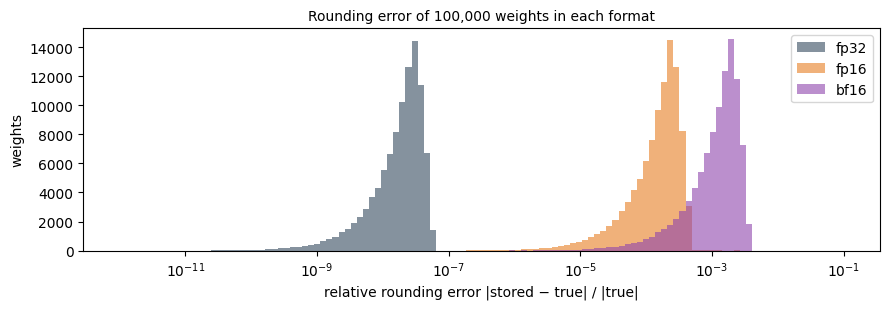

In [28]:
fig, ax = plt.subplots(figsize=(9, 3.2))
bins = torch.logspace(-12, -1, 120)
for fmt in FORMATS:
    ax.hist(rel[fmt].numpy(), bins=bins.numpy(), alpha=0.6, label=fmt, color=FMT_COLORS[fmt])
ax.set_xscale("log"); ax.set_xlabel("relative rounding error |stored − true| / |true|"); ax.set_ylabel("weights")
ax.set_title("Rounding error of 100,000 weights in each format", fontsize=10); ax.legend(); plt.tight_layout(); plt.show()

**Reading the output**

- The three histograms are separated by roughly the precision ratios from Section 4: fp16 errors are about 2¹³ = 8,192 times fp32's, and bf16 errors about 8 times fp16's.
- For fp32 and bf16, the largest relative error is exactly half the gap above 1.0, $2^{-m-1}$: 6 × 10⁻⁸ and 0.4%. Rounding to the nearest value can never be off by more than half a gap.
- **fp16's largest error is 7%, far above its typical 0.02%.** A few hundred of these weights are smaller than fp16's smallest normal number, 6.1 × 10⁻⁵. Below that value fp16 keeps fewer significant bits, so their relative error is larger (too few weights to see in the histogram). This is fp16's narrow range showing up even for weights.
- **What this means for a model:** bf16 errors of up to 0.4% per weight sound alarming, but errors in different weights mostly cancel in a sum of thousands of terms. Pretrained models run well in fp16 or bf16, which is why checkpoints are usually distributed in 16-bit. The cell below checks one layer.

In [29]:
W = torch.randn(1024, 1024, dtype=torch.float64) * 0.02          # one linear layer's weights
x = torch.randn(1024, dtype=torch.float64)                        # one input vector
y_true = W @ x
for fmt, (dtype, *_) in FORMATS.items():
    y = (W.to(dtype).double()) @ x                                # weights rounded, arithmetic exact
    print(f"{fmt}: relative error of the layer output {((y - y_true).norm() / y_true.norm()).item():.1e}")

fp32: relative error of the layer output 2.5e-08
fp16: relative error of the layer output 2.2e-04
bf16: relative error of the layer output 1.7e-03


- The relative error of the layer's **output** is about the same as the typical error of a single weight: the rounding errors do not add up to anything larger, because they point in random directions.
- This cell rounds only the weights. On a GPU the multiplication itself also runs in 16-bit, but the hardware **accumulates** the sum in fp32, which keeps this extra error small.

## 6. What goes wrong in training, and the fixes

Inference with 16-bit weights is usually fine. Training is harder, because it involves **very small numbers** (updates and gradients) and occasionally **very large** ones (activations, exponentials). We look at three failures in turn.

### Failure 1: updates that vanish

A training step changes a weight by a tiny amount: learning rate × gradient. Suppose a weight of 1.0 receives an update of +0.0001 at every step, for 1,000 steps. The correct result is 1.0 + 1000 × 0.0001 = 1.1.

**One step in fp16.** Near 1.0, fp16 can store only values 1/1024 ≈ 0.000977 apart (Section 4). The exact sum 1.0001 falls between two of them:

```
 1.0      1.0001             1.000488                1.000977
  |---------↑-------------------:-----------------------|
stored                       halfway                  stored
```

1.0001 is below the halfway point, so the sum is rounded to the nearest stored value, 1.0, and the update is lost. The next step starts from 1.0 again and loses its update the same way. Each update vanishes before the next one arrives, so they never add up.

**The rule.** An update changes a stored weight only if it is larger than **half the step** at that weight's size. Because the step grows with the number (Section 4), what matters is the update *relative to* the weight: in fp16, a weight of 1,000 (step 0.5) also ignores an update of 0.2. bf16 is worse than fp16 here, because its step near 1.0 is 1/128 ≈ 0.0078.

The cell below applies the 1,000 updates in each format. It also runs a fourth version that uses the fix, an fp32 master copy, which is explained after the output.

In [30]:
steps, update = 1000, 1e-4
history = {}
for fmt, (dtype, *_) in FORMATS.items():
    wt = torch.tensor(1.0, dtype=dtype)
    history[fmt] = []
    for _ in range(steps):
        wt = wt + torch.tensor(update, dtype=dtype)          # the update is applied in the same format
        history[fmt].append(wt.item())

# The fix: keep an fp32 "master" copy for the update; the model uses a 16-bit copy of it
master, history["bf16 + fp32 master"] = torch.tensor(1.0), []
for _ in range(steps):
    master = master + update
    history["bf16 + fp32 master"].append(master.to(torch.bfloat16).item())

for name, h in history.items():
    print(f"{name:<20} final weight: {h[-1]:.6f}")
print(f"gap above 1.0: fp16 {torch.finfo(torch.float16).eps:.6f}, bf16 {torch.finfo(torch.bfloat16).eps:.6f}")

fp32                 final weight: 1.100017
fp16                 final weight: 1.000000
bf16                 final weight: 1.000000
bf16 + fp32 master   final weight: 1.101562
gap above 1.0: fp16 0.000977, bf16 0.007812


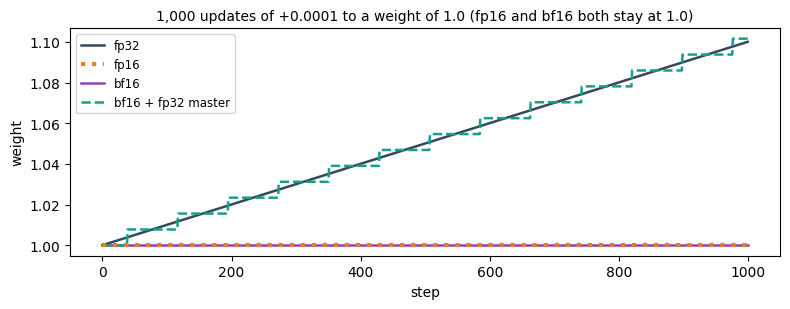

In [31]:
fig, ax = plt.subplots(figsize=(8, 3.2))
styles = {"fp32": "-", "fp16": ":", "bf16": "-", "bf16 + fp32 master": "--"}   # fp16 (dotted) lies on top of bf16
for name, h in history.items():
    ax.plot(h, styles[name], label=name, color=FMT_COLORS.get(name, "#16a085"),
            lw=3 if name == "fp16" else 1.8, zorder=3 if name == "fp16" else 2)
ax.set_xlabel("step"); ax.set_ylabel("weight"); ax.legend(fontsize=8.5)
ax.set_title("1,000 updates of +0.0001 to a weight of 1.0 (fp16 and bf16 both stay at 1.0)", fontsize=10); plt.tight_layout(); plt.show()

**Reading the output**

- **fp32 reaches 1.100017**, not exactly 1.1: even fp32 rounds a little at every addition, but the error is tiny.
- **fp16 and bf16 never move from 1.0.** All 1,000 updates were rounded away, as in the number line above. Nothing reports an error: in real training, the loss would simply stop improving.
- **This is the normal case, not a rare edge case.** Fine-tuning learning rates are around 10⁻⁵ to 10⁻⁴, so updates are typically thousands of times smaller than the weights they change. In pure 16-bit training, most of them would vanish.

**The fix: an fp32 master copy.** Keep two copies of every trainable weight:

1. An **fp32 master copy**. Its step near 1.0 is about 1.2 × 10⁻⁷, so each 0.0001 is kept and the updates add up.
2. A **16-bit copy**, made from the master at each step, which the forward and backward passes use for speed.

The optimizer always updates the master, never the 16-bit copy.

- The master grows smoothly: 1.0001, 1.0002, 1.0003, and so on. The bf16 copy stays at 1.0 until the master is close enough to the next bf16 value, 1.0078125, and then jumps. That is why the dashed line in the figure moves in steps. The 16-bit copy can hide updates for a while, but the master never loses one.
- The final **1.101562** is the master's 1.100017 rounded to the nearest bf16 value, 1 + 13/128 = 1.1015625. The error is less than half a bf16 step, and it does not grow with the number of steps.

**The cost.** The master copy is why mixed-precision training costs **16 bytes per parameter** (Lecture 1):

| Item | Bytes per parameter |
| --- | --- |
| 16-bit weight | 2 |
| 16-bit gradient | 2 |
| **fp32 master weight** | **4** |
| Adam's two fp32 moments | 8 |

LoRA avoids most of this cost. The frozen base weights are never updated, so they cannot lose updates and need no master copy: 2 bytes per parameter instead of 16. Only the small adapters pay the full cost (Section 9).

### Failure 2: overflow to infinity

fp16 cannot represent anything above 65,504. The softmax inside attention computes exponentials, and $e^{12} \approx 162{,}755$ already exceeds that.

In [32]:
logits = torch.tensor([1.0, 2.0, 12.0])
for fmt in ("fp16", "bf16"):
    z = logits.to(FORMATS[fmt][0])
    naive = torch.exp(z) / torch.exp(z).sum()                 # softmax written directly from its formula
    print(f"{fmt}: exp(logits) = {torch.exp(z).tolist()}  naive softmax = {naive.tolist()}")

z = logits.half()
stable = torch.exp(z - z.max()) / torch.exp(z - z.max()).sum()   # subtract the maximum first
print(f"fp16 with the maximum subtracted: {stable.tolist()}   torch.softmax: {torch.softmax(z, 0).tolist()}")

fp16: exp(logits) = [2.71875, 7.390625, inf]  naive softmax = [0.0, 0.0, nan]
bf16: exp(logits) = [2.71875, 7.375, 162816.0]  naive softmax = [1.6689300537109375e-05, 4.5299530029296875e-05, 1.0]
fp16 with the maximum subtracted: [1.6689300537109375e-05, 4.5418739318847656e-05, 1.0]   torch.softmax: [1.6689300537109375e-05, 4.5418739318847656e-05, 1.0]


**Reading the output**

- In fp16, $e^{12}$ becomes `inf`. The naive softmax then computes `inf / inf = NaN` for that entry, and dividing small numbers by `inf` gives 0 for the others. One NaN in the loss makes every gradient NaN, and training is ruined.
- In bf16, $e^{12}$ is simply rounded (its range reaches 3.4 × 10³⁸), and the result is correct to bf16 precision.
- **Fixes:** library code subtracts the maximum before exponentiating (`torch.softmax` does this), so the largest exponential is $e^0 = 1$. Mixed-precision tools also run overflow-prone operations (softmax, normalization, losses) in fp32. But a model whose activations naturally grow beyond 65,504 can still overflow in fp16. Some models trained in bf16 do this, which is one reason they can produce NaNs when run in fp16.

### Failure 3: gradients that underflow to zero

Many gradient values are very small. fp16's full-precision range ends at 6.1 × 10⁻⁵, and below that it can store values only down to about 6 × 10⁻⁸: anything smaller becomes exactly **0**, and that weight receives no update. The cell below draws illustrative gradient magnitudes spread evenly (on a log scale) from 10⁻¹⁰ to 10⁻³.

In [33]:
grads = 10 ** torch.empty(100_000, dtype=torch.float64).uniform_(-10, -3)    # illustrative magnitudes

def zero_fraction(g, dtype):
    return (g.to(dtype) == 0).double().mean().item()

SCALE = 2.0 ** 16                                     # PyTorch's GradScaler starts at this scale
print(f"fp16:                    {zero_fraction(grads, torch.float16):.1%} of gradients become 0")
print(f"fp16, loss scaled ×{SCALE:.0f}: {zero_fraction(grads * SCALE, torch.float16):.1%} become 0"
      f" (largest scaled value {(grads.max() * SCALE).item():.0f}, below 65,504)")
print(f"bf16:                    {zero_fraction(grads, torch.bfloat16):.1%} become 0")

fp16:                    35.1% of gradients become 0
fp16, loss scaled ×65536: 0.0% become 0 (largest scaled value 66, below 65,504)
bf16:                    0.0% become 0


**Reading the output**

- In fp16, roughly a third of these gradients (everything below about 3 × 10⁻⁸, which rounds to zero) are lost entirely.
- **The fix: loss scaling.** Multiply the loss by a large factor, here 2¹⁶ = 65,536, before the backward pass. By the chain rule, every gradient is multiplied by the same factor and moves up into fp16's range. Before the optimizer step, the gradients are converted to fp32 and divided by the factor again, so the update is unchanged.
- The scale must not be so large that the biggest gradients overflow. PyTorch's `GradScaler` adjusts it automatically: it halves the scale and **skips that step** when it finds `inf` or `NaN` gradients, and slowly increases it again after a run of good steps.
- **bf16 does not need loss scaling:** its range is the same as fp32's, so these gradients survive (coarsely rounded). This is the main practical advantage of bf16 for training.

## 7. Mixed precision in practice

**Mixed-precision training** (Micikevicius et al., 2018) combines the fixes above. The expensive matrix multiplications run in 16-bit, and the numerically delicate parts stay in fp32.

### Three phases of a training step

It is often said that "the weights and the optimizer stay in fp32, while the forward and backward passes run in 16-bit". To see why this split works, look at what each phase of one training step does:

| Phase | What it computes | Kind of work | Format |
| --- | --- | --- | --- |
| **1. Forward pass** | the layer outputs (activations) and the loss, from the inputs and the weights | huge matrix multiplications | 16-bit |
| **2. Backward pass** | the gradient of the loss with respect to every activation and weight | huge matrix multiplications (about twice the forward pass) | 16-bit |
| **3. Optimizer step** | the new weights, from the old weights and the gradients | one small element-wise update per weight | fp32 |

The **weights** are what the model learns, and they persist from one step to the next. The forward and backward passes only read them; only the optimizer step changes them.

**Why the passes can use 16-bit.** Almost all of the computation in a step is in the forward and backward passes: each layer computes something like $XW$, with millions of multiply-adds. That is where 16-bit tensor cores give their speedup. The computation also tolerates rounding. Each output is a sum of thousands of products, whose rounding errors point in random directions and mostly cancel (Section 5), and the hardware accumulates those sums in fp32. The activations and gradients of a step are used once and then discarded, so their rounding errors do not build up across steps.

**Why the weights and the optimizer need fp32.** The optimizer step computes, for every weight, $w \leftarrow w - \text{learning rate} \times \text{update}$. This is about one operation per weight, so it takes almost no time, and 16-bit would gain nothing. It does need precision: the change is thousands of times smaller than the weight and must accumulate over thousands of steps, which in 16-bit it would not (Failure 1). Adam's two moments average small values over many steps, so they are kept in fp32 for the same reason.

**How the phases connect.** At every step, values are cast at the boundaries between the phases:

1. **Cast down.** Each fp32 weight is copied to 16-bit for the matrix multiplication. The copy is temporary.
2. **Compute.** The forward and backward passes run in 16-bit and produce the gradients.
3. **Cast up.** The gradients are converted to fp32 and, for fp16, divided by the loss scale (Failure 3).
4. **Update.** The optimizer updates the fp32 master weights in fp32. The next step starts again at 1.

So "the weights stay in fp32" means that the **stored** values, the only ones that persist between steps, are always fp32. The forward and backward passes only ever see short-lived 16-bit copies of them.

An analogy: an accountant keeps the official ledger exact to the paisa (the fp32 weights and optimizer state), but does the heavy daily calculations on a fast calculator that rounds to a few digits (the 16-bit passes). Each day's rounded calculation only produces a small correction, which is entered into the exact ledger. Rounding in the daily calculations does little harm; rounding the ledger itself would lose the corrections.

The figure below shows the same cycle.

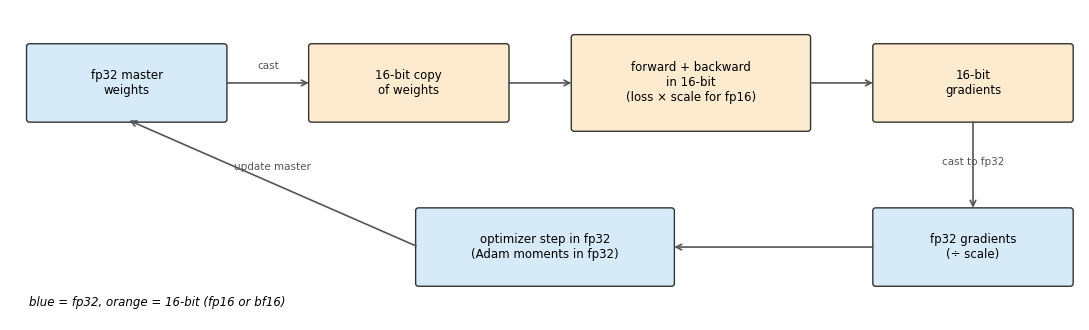

In [34]:
def draw_mixed_precision():
    fig, ax = plt.subplots(figsize=(11, 3.4))
    ax.set_xlim(0, 11); ax.set_ylim(0, 3.4); ax.axis("off")

    def box(x, y, text, color, w=2.0, h=0.8):
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.03", fc=color, ec="#333"))
        ax.text(x, y, text, ha="center", va="center", fontsize=8.5)

    def arrow(a, b, label=None, dy=0.15):
        ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color="#555", lw=1.2))
        if label:
            ax.text((a[0] + b[0]) / 2, (a[1] + b[1]) / 2 + dy, label, ha="center", fontsize=7.5, color="#555")

    fp32, half = "#d6eaf8", "#fdebd0"
    box(1.2, 2.6, "fp32 master\nweights", fp32)
    box(4.1, 2.6, "16-bit copy\nof weights", half)
    box(7.0, 2.6, "forward + backward\nin 16-bit\n(loss × scale for fp16)", half, w=2.4, h=1.0)
    box(9.9, 2.6, "16-bit\ngradients", half)
    box(9.9, 0.8, "fp32 gradients\n(÷ scale)", fp32)
    box(5.5, 0.8, "optimizer step in fp32\n(Adam moments in fp32)", fp32, w=2.6)
    arrow((2.2, 2.6), (3.1, 2.6), "cast")
    arrow((5.1, 2.6), (5.8, 2.6))
    arrow((8.2, 2.6), (8.9, 2.6))
    arrow((9.9, 2.2), (9.9, 1.2), "cast to fp32", dy=0)
    arrow((8.9, 0.8), (6.8, 0.8))
    arrow((4.2, 0.8), (1.2, 2.2), "update master")
    ax.text(0.2, 0.15, "blue = fp32, orange = 16-bit (fp16 or bf16)", fontsize=8.5, style="italic")
    plt.tight_layout(); plt.show()


draw_mixed_precision()

**Reading the figure:** the forward and backward passes, which do almost all of the computation, use 16-bit numbers and the GPU's fast 16-bit units. The weights that accumulate small updates, and the optimizer, stay in fp32 (Failure 1). With fp16 the loss is scaled and the gradients unscaled (Failure 3). Overflow-prone operations such as softmax and normalization run in fp32 (Failure 2).

### In code

```python
# Plain PyTorch: autocast chooses 16-bit or fp32 per operation; GradScaler does loss scaling (fp16 only)
scaler = torch.amp.GradScaler("cuda")
for x, y in loader:
    with torch.autocast(device_type="cuda", dtype=torch.float16):   # or torch.bfloat16 (then no scaler needed)
        loss = loss_fn(model(x), y)
    scaler.scale(loss).backward()      # multiply the loss by the scale, then backpropagate
    scaler.step(optimizer)             # unscale the gradients; skip the step if they contain inf/NaN
    scaler.update()                    # adjust the scale for the next step
    optimizer.zero_grad()

# Hugging Face Trainer: one flag does all of the above
TrainingArguments(..., fp16=True)      # on a T4;  bf16=True on Ampere or newer

# Loading a model for inference only, with no training: store the weights in 16-bit
AutoModelForCausalLM.from_pretrained(checkpoint, dtype=torch.float16)   # torch.bfloat16 where supported
```

- With `autocast`, the model's parameters stay in fp32 (the master copy). Matrix multiplications run on 16-bit copies, while operations that need range or precision, such as softmax, normalization, and losses, run in fp32.
- Loading a model with `dtype=torch.float16` is different: the weights themselves are stored in 16-bit, and there is no fp32 master copy. That is right for **inference**, and for **LoRA**, where the frozen 16-bit weights are never updated and only the small adapters are trained (`peft` keeps those in fp32). Section 9 explains this in detail.

### What mixed precision saves, and what it does not

The fp32 master copy is **extra** memory. Counting the weights, gradients, and optimizer state per trainable parameter with Adam:

| Item | Pure fp32 training | Mixed precision |
| --- | --- | --- |
| Weight | 4 | 2 (16-bit copy) + 4 (fp32 master) |
| Gradient | 4 | 2 |
| Adam's two moments | 8 | 8 |
| **Total** | **16 bytes** | **16 bytes** |

The 2 bytes saved on the gradient are spent on the 16-bit copy of the weight, so mixed precision does **not** make the model and its optimizer state smaller. Frameworks differ in where the casts happen: the figure above follows the original paper, with 16-bit gradients, while PyTorch's `autocast` keeps the parameters and their gradients in fp32 and makes the 16-bit copies of weights temporarily, operation by operation. The total is about 16 bytes either way.

Mixed precision saves two other things:

- **Time.** Tensor cores multiply 16-bit matrices several times faster than fp32 matrices, and there is half as much data to move. This is the main reason it is used.
- **Activation memory.** The forward pass saves each layer's outputs (the activations) for the backward pass, and under mixed precision they are stored in 16-bit, at half the size. Activation memory grows with batch size × sequence length × number of layers × hidden size, and with long sequences or large batches it often exceeds the memory for the weights. Halving it allows larger batches or longer sequences.

Shrinking the memory for the weights themselves needs something else: **freezing** them, so they need no master copy, gradient, or optimizer state (LoRA, Section 9), or **quantizing** them (Section 8).

### Which format on which GPU?

| GPU (architecture) | Examples | fp16 | bf16 |
| --- | --- | --- | --- |
| Pascal | P100 (offered on Kaggle) | supported, but no tensor cores | no |
| Volta, Turing | V100, **T4** (Kaggle, Colab) | fast (tensor cores) | **no native support** |
| Ampere and newer | A100, L4, RTX 30xx/40xx, H100 | fast | fast |

- **On a T4, use fp16** with loss scaling (`fp16=True`). This is why the course's Kaggle notebooks load models with `dtype=torch.float16`.
- **On Ampere or newer, prefer bf16**: same speed, no loss scaling, no overflow surprises. Many recent LLMs were trained in bf16, and their checkpoints are distributed in bf16 (Qwen2.5's are, for example).
- A model trained in bf16 usually runs well in fp16, but not always. If it produces `inf` or `NaN` in fp16, an activation is probably exceeding 65,504.

## 8. Beyond 16 bits

For storing weights, there is no need for a format that works at every scale. *Quantization* stores small integer codes plus a scale per block of weights, using 8 or 4 bits per weight. This is the subject of [Quantization and QLoRA](quantization_qlora.ipynb), which also introduces NF4, a 4-bit format designed for weights.

## 9. What this means for LoRA and QLoRA

LoRA freezes the pretrained weight matrix $W_0$ and trains two small matrices $A$ and $B$, so a layer computes $W_0x + \frac{\alpha}{r}BAx$ (see [PEFT and LoRA](peft_lora.ipynb)). The number formats above decide where each of these lives, and why.

### Frozen base weights: 16-bit, no master copy

Failure 1 (lost updates) only affects weights that are **updated**. The base weights $W_0$ are never updated, so they need no fp32 master copy, no gradient, and no optimizer state. They are loaded directly in 16-bit with `dtype=torch.float16` (or `torch.bfloat16`), at **2 bytes per parameter**. The only cost is the small rounding error of Section 5, which the model tolerates well.

### Adapters: fp32

$A$ and $B$ **are** updated at every step, by amounts far smaller than the gap between neighboring 16-bit values, so in 16-bit their updates would be lost exactly as in Failure 1. `peft` therefore keeps adapter weights in fp32 even when the base model is fp16 or bf16 (its default `autocast_adapter_dtype=True`). Each adapter parameter costs the full **16 bytes**: 4 for the fp32 weight, 4 for its fp32 gradient, and 8 for Adam's two moments. There are few adapter parameters, so this is cheap.

| Training setup | Memory for weights, gradients, and optimizer state | Qwen2.5-1.5B (1.54B parameters) |
| --- | --- | --- |
| Full fine-tuning, pure fp32 | 16 bytes × all parameters | about 24.7 GB |
| Full fine-tuning, mixed precision | 16 bytes × all parameters | about 24.7 GB |
| LoRA | 2 bytes × base parameters + 16 bytes × adapter parameters | about 3.1 GB + a few MB |

Mixed precision alone does not reduce this memory (Section 7): the first two rows are the same. LoRA's saving comes from **freezing** the base weights, so that most parameters need no master copy, gradient, or optimizer state. Activations come on top of all three rows; mixed precision halves those.

### Gradients still pass through the 16-bit base

Only $A$ and $B$ get weight gradients, but the gradient signal must flow backward through every frozen 16-bit layer to reach them. Failures 2 and 3 therefore still apply:

- **fp16 (T4):** train with `TrainingArguments(..., fp16=True)`, which turns on loss scaling so that small gradients do not underflow (Failure 3).
- **bf16 (Ampere or newer):** train with `bf16=True`. No loss scaling is needed.
- A checkpoint trained in bf16 (such as Qwen2.5) can produce `inf` or `NaN` when run in fp16 if an activation exceeds 65,504 (Failure 2).

### Merging an adapter rounds it

`merge_and_unload()` adds the update $\frac{\alpha}{r}BA$ into $W_0$ and stores the result in the base model's 16-bit format. This update is usually small compared with $W_0$, so the sum is rounded to the nearest 16-bit value and part of the change can be lost, for the same reason as in Failure 1. A merged model can therefore behave slightly differently from the unmerged one; compare a few outputs after merging.

### QLoRA: storage format and compute format

QLoRA stores the frozen $W_0$ in 4-bit NF4 (Section 8), but the GPU cannot multiply in NF4. Each layer converts $W_0$ back to a 16-bit **compute dtype** (`bnb_4bit_compute_dtype`) for every matrix multiplication. Choose it by GPU, as in Section 7: `torch.float16` on a T4, `torch.bfloat16` on Ampere or newer. The adapters stay in fp32 as in LoRA, and `prepare_model_for_kbit_training` also converts the remaining non-quantized parameters (such as normalization layers and embeddings) to fp32 for numerical stability.

### Symptoms and likely causes

| Symptom | Likely cause |
| --- | --- |
| The loss becomes `NaN` in fp16 | an activation above 65,504 (Failure 2), or loss scaling not enabled |
| Errors or very slow training with bf16 on a T4 | the T4 has no bf16 support: use fp16 |
| `ValueError: Attempting to unscale FP16 gradients.` | the trainable (adapter) weights were made fp16; keep them in fp32 |
| Training runs, but the loss does not improve | among other causes, updates lost because trained weights are held in 16-bit (Failure 1) |
| A merged model behaves slightly differently | the merged weights were rounded to 16-bit |

## 10. Summary

| Idea | What it means | Section |
| --- | --- | --- |
| Floating point | sign × 1.mantissa × 2^(exponent − bias), with the leading 1 not stored | 2 |
| Rounding is unavoidable | most decimal fractions (like 0.1) have no finite binary form | 2 |
| Exponent bits → range | fp32 and bf16: about 10⁻³⁸ to 10³⁸; fp16: about 6 × 10⁻⁵ to 65,504 | 3, 4 |
| Mantissa bits → precision | gap above 1.0 = 2⁻ᵐ: fp32 1.2 × 10⁻⁷, fp16 9.8 × 10⁻⁴, bf16 7.8 × 10⁻³ | 3, 4 |
| Gaps grow with the value | the same *relative* precision at every scale | 4 |
| Storing weights in 16-bit | small per-weight errors that largely cancel; fine for inference | 5 |
| Lost updates | small updates vanish in 16-bit; fix: fp32 master weights | 6 |
| Overflow | fp16 values above 65,504 become inf, then NaN; fix: fp32 for risky ops, or bf16 | 6 |
| Underflow | tiny fp16 gradients become 0; fix: loss scaling, or bf16 | 6 |
| Mixed precision | 16-bit compute, fp32 master weights and optimizer; fp16 on a T4, bf16 on Ampere or newer | 7 |
| LoRA and QLoRA | frozen base in 16-bit (or NF4) with no master copy; adapters in fp32; 16-bit compute | 9 |

## 11. Check your understanding

1. fp16 and bf16 both use 16 bits. Explain the trade-off each one makes, and name a situation where each one fails while the other does not.
2. What is the gap between 1024 and the next larger number in fp16? In bf16? (Hint: 1024 = 2¹⁰.)
3. A weight of 2.0 receives an update of 0.001 in bf16. What happens, and why? What does the fp32 master copy change?
4. Why does fp16 training need loss scaling, while bf16 training usually does not? What does `GradScaler` do when it finds an `inf` gradient?
5. A model trained in bf16 produces `NaN` outputs when you load it in fp16 on a T4, but works when loaded in fp32. What is the most likely cause?
6. Why does mixed-precision training with Adam need about 16 bytes per parameter? Which of those bytes are fp32, and why?
7. In LoRA on a T4, the base model is loaded in fp16 with no fp32 master copy. Why is that acceptable for the base weights, and why must the adapter weights still be fp32?
8. After LoRA training, you merge the adapter into the fp16 base model. The merged model's outputs differ slightly from the unmerged model's. Why?

<details>
<summary><b>Show answers</b></summary>

1. fp16 has 5 exponent bits and 10 mantissa bits: better precision (gap 2⁻¹⁰ above 1.0) but a range of only about 6 × 10⁻⁵ to 65,504. bf16 has 8 exponent and 7 mantissa bits: fp32's full range but coarse precision (gap 2⁻⁷). fp16 fails on large values (an activation of 70,000 becomes `inf`) and tiny gradients (become 0) where bf16 does not. bf16 fails where fine precision matters, for example small updates or telling apart values that differ by less than 0.8%, where fp16 does better.
2. The gap at $2^k$ is $2^{k-m}$. fp16: $2^{10-10} = 1$, so the next number is 1025. bf16: $2^{10-7} = 8$, so the next number is 1032.
3. Near 2.0, the bf16 gap is $2^{1-7} = 0.0156$. 2.001 is much closer to 2.0 than to 2.0156, so it rounds back to 2.0 and the update is lost. With an fp32 master copy, the update is added in fp32 (gap about 2.4 × 10⁻⁷), so it is kept. After about eight such updates, the master reaches the next bf16 value and the 16-bit copy changes.
4. fp16's smallest values (about 6 × 10⁻⁸) are much larger than many real gradients, which then become 0. Scaling the loss scales every gradient into range. bf16 shares fp32's range, so small gradients survive. `GradScaler` skips that optimizer step, halves the scale, and continues.
5. Some activation exceeds fp16's maximum of 65,504 and becomes `inf`, which then produces `NaN`. In bf16 or fp32 the value fits.
6. 2 bytes for the 16-bit weight, 2 for its 16-bit gradient, 4 for the fp32 master weight, and 4 + 4 for Adam's first and second moments in fp32. The master weight must be fp32 so that small updates are not lost (Failure 1). The moments are fp32 because they average small values over many steps, which needs the same precision.
7. The base weights are frozen: they are never updated, so there are no small updates to lose, and the only cost is a small rounding error when they are stored. The adapter weights are updated at every step by tiny amounts, which would round away in fp16 (Failure 1), so they are kept in fp32.
8. Merging computes $W_0 + \frac{\alpha}{r}BA$ and stores the result in fp16. The update is small compared with $W_0$, so the sum is rounded to the nearest fp16 value, and part of the update is lost. The unmerged model computes $W_0x$ and $\frac{\alpha}{r}BAx$ separately at every forward pass, with the adapter in fp32, so it avoids that rounding.

</details>

## References

1. IEEE, *IEEE Standard for Floating-Point Arithmetic* (IEEE 754-2019), which defines the binary32 (fp32) and binary16 (fp16) formats.
2. Goldberg, [What Every Computer Scientist Should Know About Floating-Point Arithmetic](https://doi.org/10.1145/103162.103163), ACM Computing Surveys, 1991.
3. Micikevicius et al., [Mixed Precision Training](https://arxiv.org/abs/1710.03740), 2018. (fp32 master weights, loss scaling, fp32 accumulation)
4. Kalamkar et al., [A Study of BFLOAT16 for Deep Learning Training](https://arxiv.org/abs/1905.12322), 2019.
5. Hu et al., [LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685), 2021.
6. Dettmers et al., [QLoRA: Efficient Finetuning of Quantized LLMs](https://arxiv.org/abs/2305.14314), 2023.
7. PyTorch documentation: [Automatic Mixed Precision](https://pytorch.org/docs/stable/amp.html) · [`torch.finfo`](https://pytorch.org/docs/stable/type_info.html).